# Recreación de un estudio de supervivencia con datos simulados

**Machine Learning II · Actividad final**

Artículo recreado: Kandie, A. K., Atitwa, E. B. y Nyaluke, W. (2025). *Perspectives on Judicial Efficiency: Case Study of Predictive Modeling in Kenyan High Courts*. International Journal for Court Administration, 16(2), 5. https://doi.org/10.36745/ijca.627

El notebook sigue los ocho pasos de la actividad:

1. Selección del artículo
2. Comprensión del estudio
3. Caracterización de los datos
4. Simulación
5. Recreación del análisis
6. Comparación
7. Extensión
8. Conclusión

Las funciones viven en `src/`. Aquí quedan las llamadas, los resultados y su lectura. Las tablas se guardan en `results/` y las figuras en `figures/`.

## 1. Selección del artículo y relación con el trabajo de grado

El artículo estima cuánto tarda en resolverse un caso en los tribunales superiores de Kenia (más de 90.000 casos, 2012-2022) y qué características del caso alargan ese tiempo. Para eso usa análisis de supervivencia: Kaplan-Meier, Cox de riesgos proporcionales y cuatro modelos paramétricos (Weibull, exponencial, log-normal y log-logístico), comparados con el AIC.

El trabajo de grado plantea el mismo problema en otro dominio: modelar el tiempo de ciclo de los casos de compras según sus características y, con esas distribuciones, simular la carga de trabajo para estimar cuántas personas necesita cada equipo. La correspondencia es directa:

| Tribunales (artículo) | Compras (trabajo de grado) |
|---|---|
| Caso judicial | Caso o solicitud de compra |
| Tipo de caso (civil, familia, ...) | Categoría o tipo de compra |
| Apelación | Escalamiento o reproceso del caso |
| Disposición del caso (evento) | Cierre del caso |
| Tiempo hasta la disposición | Tiempo de ciclo |
| Asignación de jueces y personal | Dimensionamiento del equipo de compras |

Recrear este artículo sirve para probar, en un caso documentado, la cadena completa que necesita la tesis: describir tiempos, ajustar modelos de duración, elegir uno y usarlo para razonar sobre capacidad.

## 2. Comprensión del estudio

**Objetivos declarados** (sección de resumen): (i) análisis exploratorio de los factores asociados al tiempo de resolución; (ii) predecir el tiempo hasta la resolución con modelos de supervivencia; (iii) comparar la precisión de Cox frente a modelos paramétricos.

**Variables usadas en los modelos**

| Variable | Tipo | Rol |
|---|---|---|
| `time_in_months` | entera, meses completos | tiempo hasta el evento |
| `Event` | binaria | 1 = caso dispuesto |
| `case_type` | factor de 5 niveles | covariable (referencia: ANTI-CORRUPTION) |
| `Appeals` | binaria | covariable (1 = caso apelado) |

**Metodología** (secciones 2 y 3): estadísticos descriptivos por grupo (Tabla 1), prueba t entre apelados y no apelados (Tabla 2), histogramas y boxplots (Figuras 1-2), curvas de Kaplan-Meier con prueba log-rank (Figura 3), Cox PH con todos los casos (Tabla 3), modelos paramétricos con `survreg` sobre los casos con duración mayor a cero (Tablas 4-7) y comparación por AIC (Tabla 8).

**Resultados principales**: familia es el tipo más lento (mediana de 35 meses) y anticorrupción y penal los más rápidos (mediana de 8 meses); los casos apelados duran más; según el AIC, Weibull es el mejor modelo y supera a Cox.

**Notación del artículo** (ecuaciones 1 a 7): Kaplan-Meier $\hat S(t)=\prod_{t_i<t}(1-d_i/n_i)$; Cox $h(t,x)=h_0(t)\,e^{\sum_j \beta_j x_j}$; Weibull $S(t)=e^{-(\theta t)^{\beta}}$ con hazard $\lambda(t)=\beta\theta(\theta t)^{\beta-1}$; exponencial $S(t)=e^{-\theta t}$, que es la Weibull con $\beta=1$.

**Equivalencias entre el código R de los autores y este proyecto**

| R (`Kandie Final Results.Rmd`) | Python (`lifelines`, en `src/modelos.py`) |
|---|---|
| `survfit(Surv(t, e) ~ g)` | `KaplanMeierFitter` por grupo |
| `ggsurvplot(..., pval = TRUE)` | `multivariate_logrank_test` |
| `coxph(...)` (empates de Efron) | `CoxPHFitter` (empates de Efron) |
| `survreg(..., dist = "weibull")` | `WeibullAFTFitter` |
| `survreg(..., dist = "exponential")` | `ExponentialAFTFitter` (definido en `src/modelos.py`) |
| `survreg(..., dist = "lognormal")` | `LogNormalAFTFitter` |
| `survreg(..., dist = "loglogistic")` | `LogLogisticAFTFitter` |
| `AIC(...)` | `AIC_` (paramétricos), `AIC_partial_` (Cox) |

In [1]:
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as cfg
from src import simulacion as sim
from src import modelos as m
from src import eda, pipeline
from src import extension as ext
from src import graficos as g

g.estilo()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
cfg.RESULTS.mkdir(exist_ok=True)
cfg.FIGURES.mkdir(exist_ok=True)
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: /home/claude/proyecto


## 3. Caracterización de los datos

**Lo que reporta el artículo**

| Característica | Valor reportado | Fuente |
|---|---|---|
| Número de registros | 91.405 | Sección 3.1.1 |
| Periodo | 2012-2022 | Sección 2.1 |
| Niveles de `case_type` | 5 (anti-corruption, civil, constitutional, criminal, family) | Sección 3.1.1 |
| Media, mediana, mínimo, máximo y DE del tiempo por tipo y por apelación | ver Tabla 1 | Tabla 1 |
| Prueba t por apelación | t = −20.67, gl = 48.116 | Tabla 2 |
| Coeficientes de los modelos | ver Tablas 3-7 | Tablas 3-7 |
| AIC por modelo | ver Tabla 8 | Tabla 8 |

**Lo que el artículo no reporta y la simulación necesita**: cuántos casos hay de cada tipo, cuántos se apelan, cómo llegan los casos en el tiempo, cómo se definió la muestra (qué casos entran) y qué forma tiene la distribución del tiempo. Cada uno se declara como supuesto:

In [2]:
supuestos = pd.DataFrame(cfg.SUPUESTOS, index=["Supuesto", "Justificación"]).T
supuestos.to_csv(cfg.RESULTS / "supuestos.csv")
display(supuestos)

,Supuesto,Justificación
S1,Proporción de casos por tipo,No reportada en el artículo; tomada del conjun...
S2,Proporción de apelaciones por tipo,No reportada; tomada del conjunto compartido p...
S3,Efecto de la apelación sobre el tiempo,Razón de tiempos exp(0.130)=1.139 tomada de la...
S4,Llegada de casos,Radicación uniforme entre ene-2012 y dic-2022;...
S5,Mecanismo de observación,Solo entran casos dispuestos entre ene-2018 y ...
S6,Distribución del tiempo latente,"Weibull por tipo de caso, calibrada contra med..."
S7,Medición del tiempo,"Meses completos (piso), lo que produce duracio..."


Los autores compartieron su base y su código. La base **no** se usa para generar los datos simulados (salvo para fijar los supuestos S1, S2 y S5, que el artículo no reporta). Se usa como referencia en la sección 6, para saber si una diferencia viene de la simulación o del propio artículo. El archivo no se versiona en el repositorio (ver README); si no está en `data/raw/`, el notebook usa las tablas ya guardadas en `results/`.

La revisión de la base deja tres hechos que el artículo no menciona:

In [3]:
HAY_REAL = cfg.ARCHIVO_REAL.exists()
if HAY_REAL:
    real = sim.cargar_real()
    hechos = pd.Series({
        "Registros en la base": len(real),
        "Registros según el artículo": cfg.N_ARTICULO,
        "Casos con Event = 0 (censurados)": int((real["Event"] == 0).sum()),
        "Año de disposición mínimo": int(real["disposal_year"].min()),
        "% dispuestos en 2018-2022": round(100 * real["disposal_year"].between(2018, 2022).mean(), 2),
        "% con 0 meses de duración": round(100 * (real["time_in_months"] == 0).mean(), 1),
    }, name="valor")
    hechos.to_csv(cfg.RESULTS / "real_hechos_base.csv")
    display(hechos.to_frame())
    display(eda.distribucion_tipos(real).assign(
        apelados_pct=real.groupby("case_type")["Appeals"].mean().mul(100).round(1)))
else:
    print("Base real no disponible: se usan las tablas guardadas en results/.")
    display(pd.read_csv(cfg.RESULTS / "real_hechos_base.csv", index_col=0))

,valor
Registros en la base,92405.00
Registros según el artículo,91405.00
Casos con Event = 0 (censurados),1.00
Año de disposición mínimo,2017.00
% dispuestos en 2018-2022,99.99
% con 0 meses de duración,12.10


,n,porcentaje,apelados_pct
case_type,,,
ANTI-CORRUPTION,418,0.5,21.5
CIVIL,31148,33.7,41.2
CONSTITUTIONAL,7036,7.6,0.4
CRIMINAL,31707,34.3,29.9
FAMILY,22096,23.9,2.7


1. **La base tiene 92.405 registros**, no 91.405. Se simula con la cifra del artículo.
2. **Prácticamente no hay censura**: un solo caso tiene `Event = 0`. El artículo justifica el análisis de supervivencia por su capacidad de manejar censura, pero en estos datos no la hay.
3. **La base contiene casos dispuestos entre 2018 y 2022**, aunque se radicaron desde 2012. Es decir, la muestra se definió por fecha de cierre. Un caso radicado en 2016 que seguía abierto a finales de 2022 no aparece, y uno radicado en 2012 y cerrado en 2015 tampoco. Esta es la base del supuesto S5 y de la extensión de la sección 7.

## 4. Simulación

### 4.1 Proceso generador

Cada caso latente $i$ recibe:

- un tipo $c_i$ con las proporciones de S1 y una marca de apelación $A_i \sim \text{Bernoulli}(p_{c_i})$ (S2);
- una fecha de radicación $F_i \sim U(0, 132)$ meses desde enero de 2012 (S4);
- una duración latente Weibull con forma y escala propias del tipo (S6), y un efecto multiplicativo de la apelación (S3):

$$T_i = \lambda_{c_i}\, e^{\gamma A_i}\, E_i^{1/k_{c_i}}, \qquad E_i \sim \text{Exp}(1)$$

El caso entra a la base solo si $72 \le F_i + T_i < 132$, es decir, si se dispuso entre 2018 y 2022 (S5), y se registra $\lfloor T_i \rfloor$ meses (S7).

En la notación del artículo, $k_c$ es el $\beta$ de la ecuación 3 y $\lambda_c$ es $1/\theta$. La forma $e^{\gamma A}$ es un modelo de tiempo de vida acelerado (AFT): apelar multiplica la duración por $e^{\gamma}$.

### 4.2 Calibración

Los parámetros no se fijan a mano. Se buscan por simulación para que los datos **observados** (después de la ventana y del redondeo) reproduzcan lo que reporta el artículo:

- **Nivel interno**: para cada tipo, $(k_c, \lambda_c)$ se ajustan con Nelder-Mead para reproducir media, mediana y DE de la Tabla 1, usando números aleatorios comunes para que la función objetivo sea estable.
- **Nivel externo**: $\gamma$ se ajusta por bisección para reproducir la diferencia de medias entre apelados y no apelados de la Tabla 1 (30.08 − 26.22 = 3.86 meses).

Calibrar contra los datos observados, y no contra la distribución latente, es necesario porque la ventana de 2018-2022 recorta las duraciones largas: si se usaran directamente las medias de la Tabla 1 como medias latentes, los datos simulados quedarían más cortos que los del artículo.

La calibración tarda cerca de un minuto. Si `data/parametros_calibrados.csv` ya existe, se carga.

In [4]:
REGENERAR = not cfg.ARCHIVO_PARAMETROS.exists()

if REGENERAR:
    parametros = sim.calibrar()
    historial = pd.DataFrame(parametros.attrs["historial_gamma"], columns=["gamma", "brecha"])
    parametros.to_csv(cfg.ARCHIVO_PARAMETROS, index=False)
    historial.to_csv(cfg.RESULTS / "calibracion_gamma.csv", index=False)
    latente = sim.generar_poblacion_latente(parametros)
    latente.to_csv(cfg.ARCHIVO_LATENTE.with_suffix(".csv.gz"), index=False, compression="gzip")
    base = sim.base_tipo_articulo(latente)
    base.to_csv(cfg.ARCHIVO_SIMULADO, index=False)
else:
    parametros = pd.read_csv(cfg.ARCHIVO_PARAMETROS)
    historial = pd.read_csv(cfg.RESULTS / "calibracion_gamma.csv")
    latente = pd.read_csv(cfg.ARCHIVO_LATENTE.with_suffix(".csv.gz"))
    base = pd.read_csv(cfg.ARCHIVO_SIMULADO)

print(f"Casos latentes generados: {len(latente):,}")
print(f"Casos en la base simulada (dispuestos 2018-2022): {len(base):,}")
display(parametros[["case_type", "forma_k", "escala_lambda", "gamma",
                    "media_obj", "media_sim", "mediana_obj", "sd_obj", "sd_sim"]])

Casos latentes generados: 233,253
Casos en la base simulada (dispuestos 2018-2022): 91,405


,case_type,forma_k,escala_lambda,gamma,media_obj,media_sim,mediana_obj,sd_obj,sd_sim
0,ANTI-CORRUPTION,0.860,11.697,0.671,14.22,13.801,8,16.01,16.268
1,CIVIL,1.000,31.757,0.671,30.89,30.488,23,27.11,25.883
2,CONSTITUTIONAL,0.840,23.941,0.671,21.54,21.547,14,22.24,22.236
3,CRIMINAL,0.678,12.924,0.671,15.91,16.160,8,20.81,20.624
4,FAMILY,0.999,81.709,0.671,40.19,40.442,35,30.14,29.483


In [5]:
base.head()

,id,case_type,Appeals,filed_date,filed_year,disposal_date,disposal_year,time_in_years,time_in_months,Event
0,1,ANTI-CORRUPTION,1,2014-04-28,2014,2019-02-15,2019,4,57,1
1,4,ANTI-CORRUPTION,0,2017-04-03,2017,2018-03-24,2018,0,11,1
2,5,ANTI-CORRUPTION,0,2016-04-05,2016,2019-06-02,2019,3,37,1
3,7,ANTI-CORRUPTION,0,2020-01-19,2020,2020-04-22,2020,0,3,1
4,9,ANTI-CORRUPTION,0,2021-06-05,2021,2021-08-08,2021,0,2,1


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


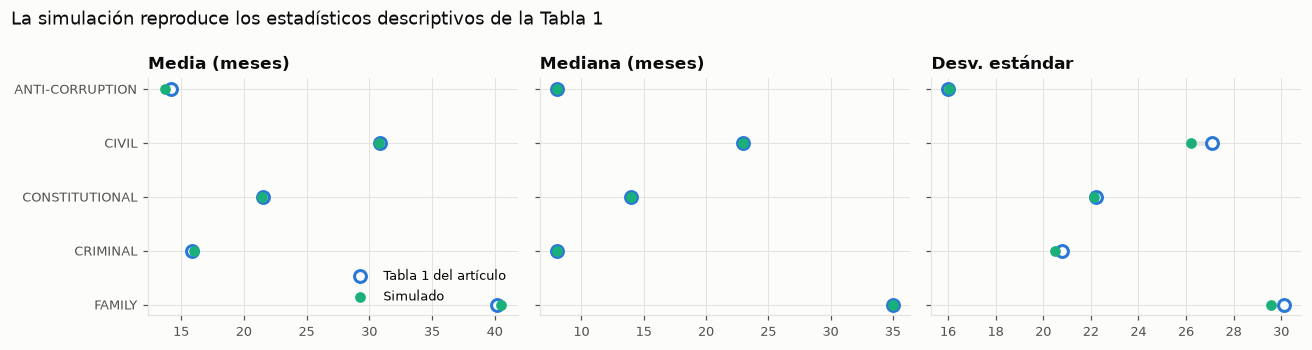

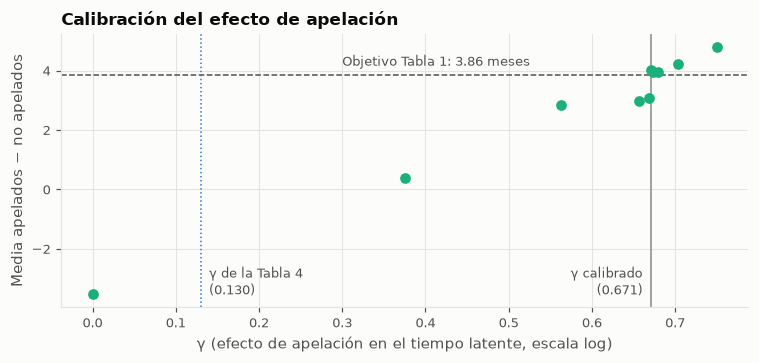

gamma calibrado = 0.671  ->  razón de tiempos exp(gamma) = 1.96


In [6]:
comp_t1 = eda.comparar_tabla1(base, real if HAY_REAL else None)
comp_t1.to_csv(cfg.RESULTS / "comparacion_tabla1.csv")
g.calibracion(parametros, comp_t1)
plt.show()
gamma = parametros["gamma"].iloc[0]
objetivo = cfg.TABLA1["Appeals(1)"][0] - cfg.TABLA1["Non-Appeals(0)"][0]
g.brecha_apelacion(historial, objetivo, gamma)
plt.show()
print(f"gamma calibrado = {gamma:.3f}  ->  razón de tiempos exp(gamma) = {np.exp(gamma):.2f}")

**Lectura.** Los cinco tipos quedan a menos de un mes de la media, la mediana y la DE del artículo. Las formas calibradas $k_c$ están entre 0.68 (penal) y 1.0 (civil y familia): el riesgo de resolución es decreciente en el tiempo para penal y anticorrupción (muchos casos se cierran rápido y el resto se estanca) y casi constante para civil y familia.

La segunda figura muestra algo que vale la pena llevar a la discusión: con el efecto de apelación que estima el propio artículo en la Tabla 4 ($\gamma = 0.130$), la simulación produce apelados **más cortos** que los no apelados, lo contrario de la Tabla 1. Para reproducir la Tabla 1 hace falta $\gamma \approx 0.67$. La explicación es que las apelaciones se concentran en civil (41 %) y penal (30 %) y casi no existen en familia (3 %) ni en constitucional (0.4 %): la diferencia de medias de la Tabla 1 mezcla el efecto de apelar con la composición por tipo. Un solo $\gamma$ común no puede reproducir a la vez la Tabla 1 y la Tabla 4, lo que sugiere que en los datos reales el efecto de la apelación cambia según el tipo de caso.

## 5. Recreación del análisis

Se aplica a la base simulada el mismo procedimiento del Rmd de los autores, en el mismo orden. `pipeline.correr` ajusta todo de una vez (unos 30 segundos) y las secciones siguientes muestran cada pieza.

In [7]:
res_sim = pipeline.correr(base)
pipeline.guardar(res_sim, "sim")
print(f"n total = {res_sim['n']:,}   |   n con duración > 0 (clean_data) = {res_sim['n_sin_ceros']:,}")

n total = 91,405   |   n con duración > 0 (clean_data) = 84,985


### 5.1 Análisis exploratorio (Tabla 1, Tabla 2, Figuras 1 y 2)

In [8]:
display(eda.distribucion_tipos(base))
display(res_sim["tabla1_tipo"])
display(res_sim["tabla1_apelacion"])

,n,porcentaje
case_type,,
ANTI-CORRUPTION,411,0.4
CIVIL,30813,33.7
CONSTITUTIONAL,6956,7.6
CRIMINAL,31361,34.3
FAMILY,21864,23.9


,media,mediana,minimo,maximo,de,n
case_type,,,,,,
ANTI-CORRUPTION,13.703,8.0,0,88,16.021,411
CIVIL,30.747,23.0,0,130,26.205,30813
CONSTITUTIONAL,21.442,14.0,0,128,22.155,6956
CRIMINAL,16.046,8.0,0,130,20.503,31361
FAMILY,40.511,35.0,0,130,29.592,21864


,media,mediana,minimo,maximo,de,n
Appeals,,,,,,
0,26.336,17.0,0,130,26.335,70486
1,30.348,22.0,0,130,27.943,20919


In [9]:
display(res_sim["prueba_t"].to_frame("simulado"))

,simulado
t,-1.847e+01
gl,3.272e+04
p,8.089e-76
ic_inf,-4.438e+00
ic_sup,-3.586e+00
media_0,2.634e+01
media_1,3.035e+01
de_0,2.633e+01
de_1,2.794e+01


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


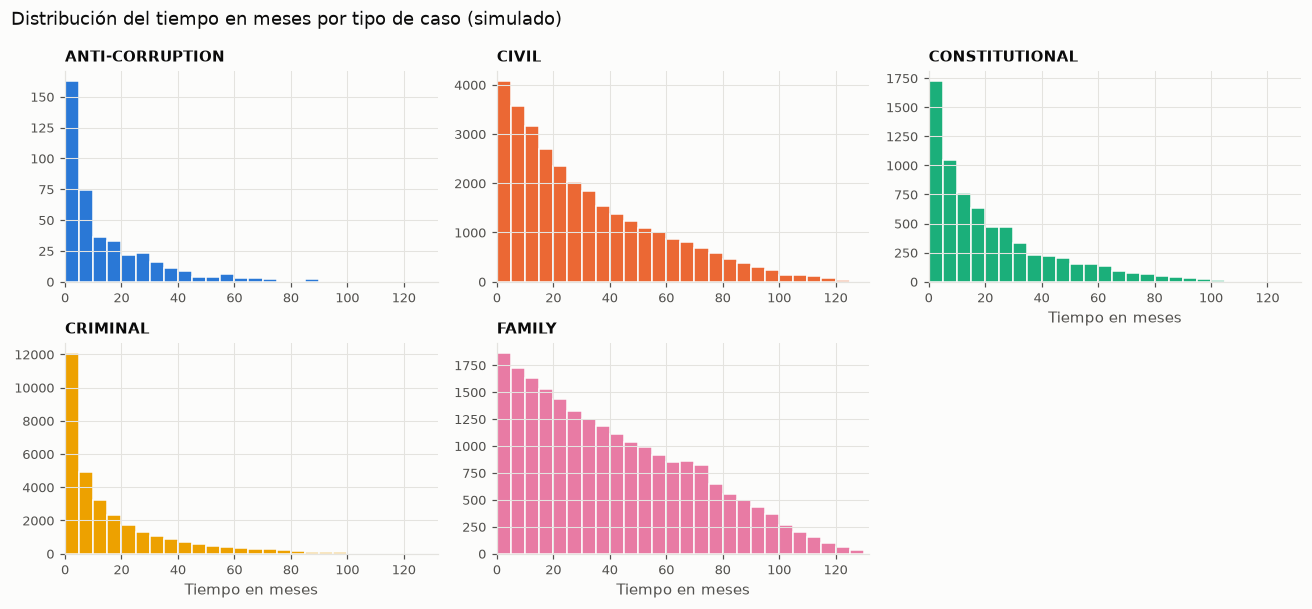

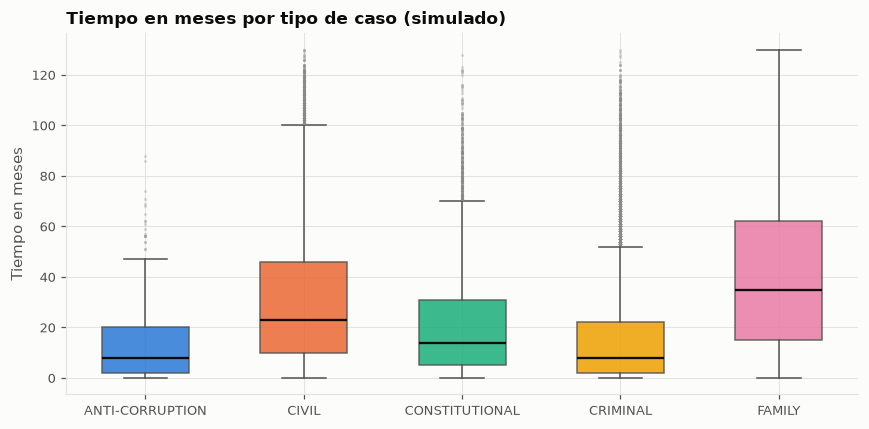

In [10]:
g.histogramas(base, "Distribución del tiempo en meses por tipo de caso (simulado)", "03_histogramas_simulado")
plt.show()
g.boxplot_tipos(base, "Tiempo en meses por tipo de caso (simulado)", "04_boxplot_simulado")
plt.show()

Como en las Figuras 1 y 2 del artículo, todas las distribuciones tienen sesgo a la derecha. Familia y civil tienen las colas más largas; penal y anticorrupción concentran la masa en los primeros meses. La prueba t de Welch da apelados más largos que no apelados ($t \approx -18.5$), en la misma dirección que la Tabla 2.

### 5.2 Kaplan-Meier y log-rank (Figura 3)

Igual que en el Rmd, las curvas se estiman sobre los casos con duración mayor a cero (`clean_data`).

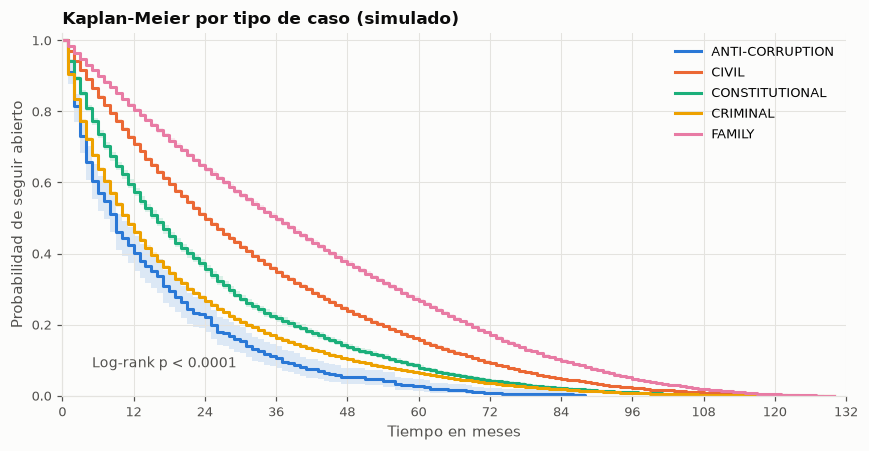

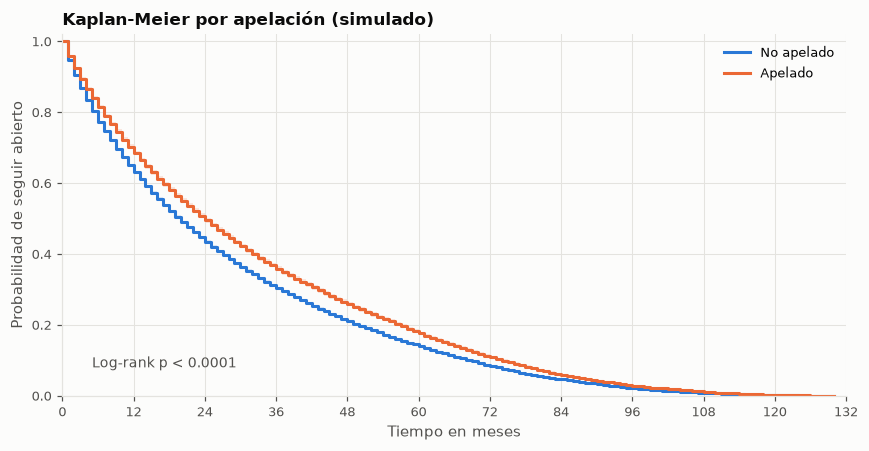

In [11]:
limpio = m.sin_ceros(base)
km_tipo = m.km_por_grupo(limpio, "case_type")
g.km(km_tipo, cfg.COLORES_TIPO, "Kaplan-Meier por tipo de caso (simulado)",
     "05_km_tipo_simulado", p_valor=res_sim["logrank_tipo"])
plt.show()
km_apel = m.km_por_grupo(limpio, "Appeals")
g.km(km_apel, cfg.COLORES_APELACION, "Kaplan-Meier por apelación (simulado)",
     "06_km_apelacion_simulado", p_valor=res_sim["logrank_apelacion"],
     etiquetas={0: "No apelado", 1: "Apelado"})
plt.show()

In [12]:
km_global = m.tabla_km(m.km_por_grupo(limpio)["Global"])
km_global.to_csv(cfg.RESULTS / "sim_km_global_tiempos.csv", index=False)
display(km_global)
display(pd.Series({t: k.median_survival_time_ for t, k in km_tipo.items()}, name="mediana KM (meses)").to_frame())

,mes,S(t),IC_inf,IC_sup
0,12,0.643,0.640,0.646
1,24,0.448,0.445,0.452
2,36,0.317,0.314,0.320
3,48,0.221,0.218,0.224
4,60,0.148,0.146,0.150
5,72,0.089,0.087,0.091
6,84,0.049,0.048,0.050
7,96,0.023,0.022,0.024
8,108,0.009,0.008,0.009
9,120,0.002,0.001,0.002


,mediana KM (meses)
ANTI-CORRUPTION,9.0
CIVIL,24.0
CONSTITUTIONAL,16.0
CRIMINAL,11.0
FAMILY,36.0


El orden de las curvas es el del artículo: anticorrupción cae primero, luego penal y constitucional, civil después y familia al final. La prueba log-rank rechaza la igualdad de curvas entre tipos ($p < 0.0001$) y entre apelados y no apelados.

### 5.3 Cox de riesgos proporcionales (Tabla 3)

Como en el Rmd, Cox se ajusta con **todos** los casos, incluidos los de 0 meses. Un HR menor que 1 significa menor riesgo de resolución, es decir, casos más lentos que la referencia (anticorrupción, no apelado).

In [13]:
display(res_sim["tabla_cox"])

,coef,HR,IC95_inf,IC95_sup,p
Appeals,-0.367,0.693,0.682,0.705,0.000e+00
CIVIL,-0.741,0.477,0.432,0.525,3.066e-50
CONSTITUTIONAL,-0.524,0.592,0.536,0.654,5.979e-25
CRIMINAL,-0.138,0.871,0.790,0.960,5.442e-03
FAMILY,-1.186,0.305,0.277,0.337,7.757e-125


### 5.4 Modelos paramétricos (Tablas 4 a 7)

Como en el Rmd, se ajustan sobre `clean_data` con la parametrización de `survreg`: $\log T = X\beta + \sigma W$. La columna `exp(coef)` es una **razón de tiempos**. El parámetro de escala $\sigma$ (el `Scale` que imprime `survreg`) no aparece en el artículo; aquí se reporta aparte.

In [14]:
for modelo, tabla in res_sim["tablas_aft"].items():
    print(f"\n{modelo}   (Scale = {res_sim['escalas'][modelo]:.3f})")
    display(tabla)


Weibull   (Scale = 0.919)


,coef,exp(coef),se,z,p
Intercept,2.666,14.377,0.047,56.244,0.000e+00
Appeals,0.312,1.366,0.008,38.796,0.000e+00
CIVIL,0.687,1.988,0.048,14.422,3.782e-47
CONSTITUTIONAL,0.508,1.662,0.049,10.428,1.840e-25
CRIMINAL,0.209,1.233,0.048,4.386,1.155e-05
FAMILY,1.071,2.918,0.048,22.408,3.278e-111



Exponential   (Scale = 1.000)


,coef,exp(coef),se,z,p
Intercept,2.623,13.771,0.052,50.887,0.000e+00
Appeals,0.317,1.373,0.009,36.237,1.613e-287
CIVIL,0.700,2.015,0.052,13.513,1.319e-41
CONSTITUTIONAL,0.516,1.675,0.053,9.726,2.333e-22
CRIMINAL,0.207,1.230,0.052,3.997,6.425e-05
FAMILY,1.091,2.977,0.052,20.988,8.490e-98



Log-normal   (Scale = 1.131)


,coef,exp(coef),se,z,p
Intercept,2.022,7.553,0.058,34.696,9.160e-264
Appeals,0.361,1.435,0.010,36.567,9.487e-293
CIVIL,0.840,2.316,0.059,14.324,1.556e-46
CONSTITUTIONAL,0.569,1.766,0.060,9.485,2.413e-21
CRIMINAL,0.155,1.168,0.059,2.648,8.106e-03
FAMILY,1.309,3.701,0.059,22.265,8.128e-110



Log-logistic   (Scale = 0.647)


,coef,exp(coef),se,z,p
Intercept,2.022,7.557,0.060,33.457,2.014e-245
Appeals,0.384,1.468,0.010,38.622,0.000e+00
CIVIL,0.924,2.520,0.061,15.208,3.129e-52
CONSTITUTIONAL,0.649,1.913,0.062,10.443,1.571e-25
CRIMINAL,0.197,1.218,0.061,3.240,1.197e-03
FAMILY,1.414,4.113,0.061,23.221,2.811e-119


### 5.5 Comparación por AIC (Tabla 8)

In [15]:
display(res_sim["aic"])

,gl,logLik,AIC,n,verosimilitud
modelo,,,,,
Cox PH,5,-945912.770,1.892e+06,91405,parcial
Weibull,7,-366939.452,7.339e+05,84985,completa
Exponential,6,-367404.010,7.348e+05,84985,completa
Log-normal,7,-371094.151,7.422e+05,84985,completa
Log-logistic,7,-371994.694,7.440e+05,84985,completa


El orden de los paramétricos coincide con el del artículo: Weibull < exponencial < log-normal < log-logístico. Cox aparece con un AIC cerca de 2.5 veces mayor, igual que en la Tabla 8. La sección 6.5 explica por qué ese número de Cox no debe compararse con los otros.

## 6. Comparación con el artículo

### 6.1 Réplica con los datos reales como referencia

Antes de comparar la simulación con el artículo conviene saber si el código de este proyecto reproduce el artículo cuando recibe los datos originales. Si lo hace, cualquier diferencia posterior se debe a la simulación y no a la herramienta (R frente a Python).

In [16]:
if HAY_REAL:
    res_real = pipeline.correr(real)
    pipeline.guardar(res_real, "real")
else:
    res_real = pipeline.cargar("real")

verificacion = pd.DataFrame({
    "artículo": [cfg.TABLA3["FAMILY"][1], cfg.TABLAS_AFT["Weibull"]["FAMILY"][0], cfg.TABLA8["Weibull"][1], cfg.TABLA8["Cox PH"][1]],
    "réplica Python con datos reales": [res_real["tabla_cox"].loc["FAMILY", "HR"],
                                        res_real["tablas_aft"]["Weibull"].loc["FAMILY", "coef"],
                                        res_real["aic"].loc["Weibull", "AIC"], res_real["aic"].loc["Cox PH", "AIC"]],
}, index=["HR Cox, familia", "Coef. Weibull, familia", "AIC Weibull", "AIC Cox"])
display(verificacion)

,artículo,réplica Python con datos reales
"HR Cox, familia",3.310e-01,3.311e-01
"Coef. Weibull, familia",9.920e-01,9.916e-01
AIC Weibull,7.134e+05,7.134e+05
AIC Cox,1.915e+06,1.915e+06


La réplica con `lifelines` reproduce las Tablas 3 a 8 del artículo hasta el tercer decimal (en el log-logístico hay diferencias de 0.003 por la convergencia del optimizador). Esto confirma que el artículo usó exactamente el código del Rmd y que las diferencias de las siguientes secciones vienen de los supuestos de la simulación.

### 6.2 Datos: Tabla 1, Tabla 2 y curvas de supervivencia

In [17]:
display(comp_t1)
comp_t2 = eda.comparar_tabla2(res_sim["prueba_t"], res_real.get("prueba_t"))
comp_t2.to_csv(cfg.RESULTS / "comparacion_tabla2.csv")
display(comp_t2)

,media_art,media_sim,mediana_art,mediana_sim,max_art,max_sim,de_art,de_sim,media_real,de_real
grupo,,,,,,,,,,
ANTI-CORRUPTION,14.22,13.703,8,8.0,72,88,16.01,16.021,14.218,16.013
CIVIL,30.89,30.747,23,23.0,130,130,27.11,26.205,30.887,27.109
CONSTITUTIONAL,21.54,21.442,14,14.0,129,128,22.24,22.155,21.538,22.239
CRIMINAL,15.91,16.046,8,8.0,126,130,20.81,20.503,15.908,20.810
FAMILY,40.19,40.511,35,35.0,129,130,30.14,29.592,40.192,30.143
Non-Appeals(0),26.22,26.336,15,17.0,130,130,28.47,26.335,26.223,28.473
Appeals(1),30.08,30.348,24,22.0,129,130,23.09,27.943,30.081,23.091


,articulo,simulado,real
t,-20.67,-18.474,-20.669
gl,48116.00,32724.705,48115.956
ic_inf,-4.22,-4.438,-4.223
ic_sup,-3.49,-3.586,-3.492
media_0,26.22,26.336,26.223
media_1,30.08,30.348,30.081
de_0,4.22,26.335,28.473
de_1,3.49,27.943,23.091


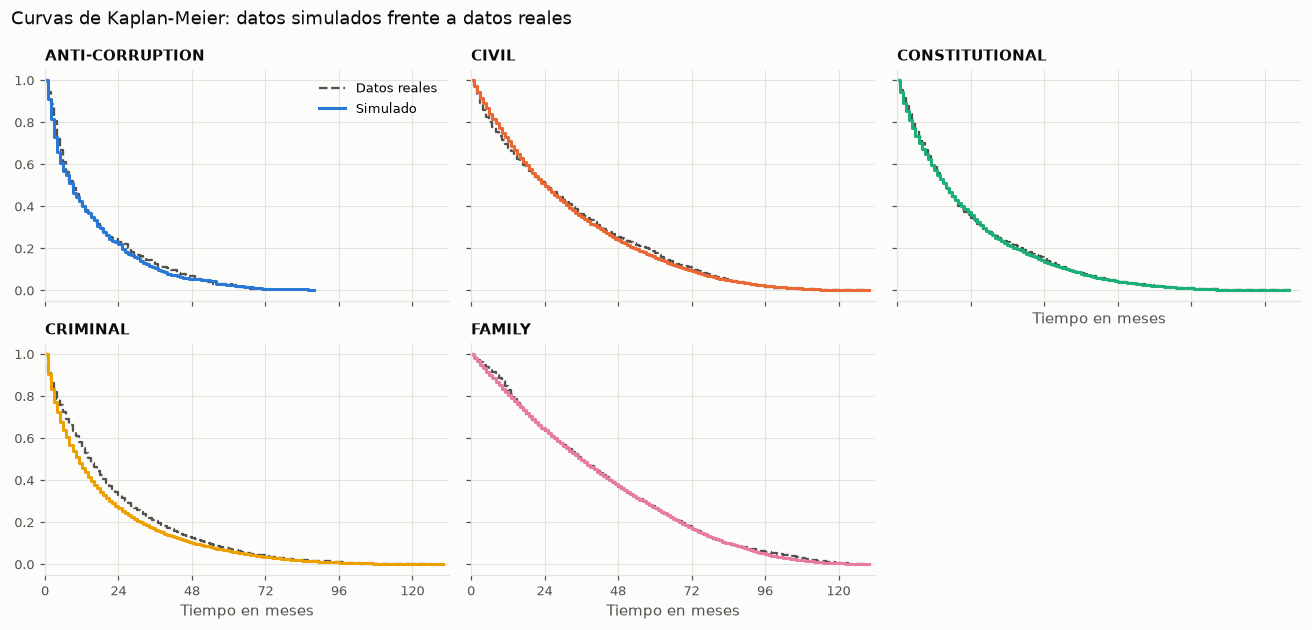

In [18]:
g.km_sim_vs_real(res_sim["km_largo"], res_real["km_largo"])
plt.show()

Las medias, medianas y DE por tipo coinciden por construcción, porque fueron el objetivo de la calibración. Las curvas completas, que no se usaron para calibrar, también quedan cerca. La diferencia visible está en penal: la curva real cae mucho más rápido en el primer mes. En la base real el 27 % de los casos penales se resuelve en 0 meses, frente al 15 % simulado; una Weibull de una sola forma no reproduce esa masa de cierres inmediatos y a la vez la cola de más de 100 meses.

En la Tabla 2, las DE del artículo (4.22 y 3.49) no son desviaciones estándar: coinciden con los límites del intervalo de confianza de la diferencia de medias. Las DE reales son 28.47 y 23.09, como aparece en la Tabla 1.

### 6.3 Coeficientes de los modelos

In [19]:
comp_cox = eda.comparar_cox(res_sim["tabla_cox"], res_real["tabla_cox"])
comp_aft = eda.comparar_aft(res_sim["tablas_aft"], res_real["tablas_aft"])
comp_aic = eda.comparar_aic(res_sim["aic"], res_real["aic"])
comp_cox.to_csv(cfg.RESULTS / "comparacion_cox.csv")
comp_aft.to_csv(cfg.RESULTS / "comparacion_aft.csv", index=False)
comp_aic.to_csv(cfg.RESULTS / "comparacion_aic.csv")
display(comp_cox)
display(comp_aft.pivot(index="covariable", columns="modelo", values=["coef_art", "coef_sim"]).round(3))
display(comp_aic)

,coef_art,coef_real,coef_sim,HR_art,HR_real,HR_sim,IC_sim,p_sim
Appeals,-0.312,-0.312,-0.367,0.732,0.732,0.693,"[0.682, 0.705]",0.000e+00
CIVIL,-0.690,-0.690,-0.741,0.502,0.502,0.477,"[0.432, 0.525]",3.066e-50
CONSTITUTIONAL,-0.470,-0.470,-0.524,0.625,0.625,0.592,"[0.536, 0.654]",5.979e-25
CRIMINAL,-0.073,-0.073,-0.138,0.930,0.930,0.871,"[0.790, 0.960]",5.442e-03
FAMILY,-1.105,-1.105,-1.186,0.331,0.331,0.305,"[0.277, 0.337]",7.757e-125


coef_art                                    coef_sim                                
modelo         Exponential Log-logistic Log-normal Weibull Exponential Log-logistic Log-normal Weibull
covariable                                                                                            
Appeals              0.153        0.484      0.506   0.130       0.317        0.384      0.361   0.312
CIVIL                0.679        0.704      0.627   0.674       0.700        0.924      0.840   0.687
CONSTITUTIONAL       0.443        0.588      0.537   0.432       0.516        0.649      0.569   0.508
CRIMINAL             0.307        0.237      0.181   0.310       0.207        0.197      0.155   0.209
FAMILY               1.017        1.330      1.259   0.992       1.091        1.414      1.309   1.071
Intercept            2.714        2.125      2.110   2.767       2.623        2.022      2.022   2.666

,AIC_art,AIC_sim,AIC_real,rango_art,rango_sim
Cox PH,1.915e+06,1.892e+06,1.915e+06,5,5
Weibull,7.134e+05,7.339e+05,7.134e+05,1,1
Exponential,7.146e+05,7.348e+05,7.146e+05,2,2
Log-normal,7.219e+05,7.422e+05,7.219e+05,3,3
Log-logistic,7.237e+05,7.440e+05,7.237e+05,4,4


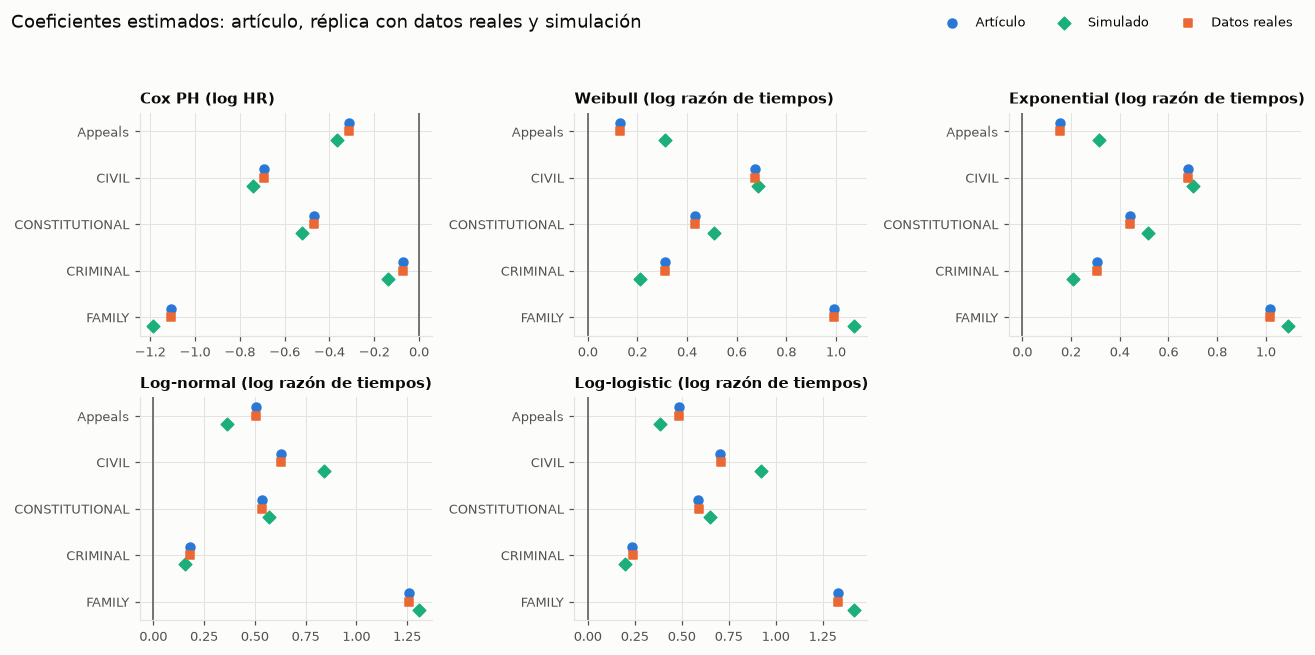

In [20]:
g.coeficientes(comp_aft, comp_cox)
plt.show()

**Qué se recrea.** Todos los signos coinciden en los cinco modelos. El orden de los tipos de caso también: familia es el más lento, luego civil, constitucional y penal, frente a anticorrupción. Los HR de Cox para civil, constitucional y familia quedan a menos de 0.04 de los del artículo, y el ranking por AIC es idéntico.

**Qué no se recrea y por qué**

1. **Apelación.** En todos los modelos el efecto simulado es mayor que el del artículo (Weibull: 0.31 frente a 0.13). La simulación usa un $\gamma$ común calibrado contra la Tabla 1, mientras que en los datos reales el efecto cambia según el tipo (en familia los apelados son incluso más cortos). Un modelo de efectos principales promedia esos efectos de forma distinta a como lo hace la diferencia de medias marginal.
2. **Penal.** En los datos reales penal tiene un coeficiente mayor en Weibull (0.31 frente a 0.21) y un HR de Cox no significativo (0.93, $p = 0.14$); en la simulación el HR es 0.87 y sí es significativo. Se explica por la masa de cierres a 0 meses que la Weibull no reproduce (punto anterior) y por el filtro `time_in_months > 0`, que elimina el 27 % de los casos penales reales pero solo el 15 % de los simulados.
3. **Escala de los AIC.** Los valores absolutos difieren (733.893 frente a 713.383 en Weibull) porque la base simulada deja 84.985 casos con duración positiva y la real 81.266. El AIC depende del número de observaciones, así que solo el orden entre modelos es comparable.
4. **Llegada de casos.** S4 supone radicación uniforme; en la base real las radicaciones crecen hasta 2018 y luego bajan, y las disposiciones aumentan cada año hasta 2022. Esto cambia qué duraciones caben en la ventana de observación.

### 6.4 Lo que la recreación revela sobre la metodología del artículo

Recrear el análisis obliga a entender cada número, y en ese proceso aparecen cuatro problemas de interpretación en el artículo. No cambian los datos, pero sí las conclusiones.

#### a) Los coeficientes de `survreg` son razones de tiempo, no de riesgo

El artículo lee los coeficientes positivos de las Tablas 4 a 7 como "mayor riesgo de resolución o menor duración" y por eso concluye que el resultado de familia es "contraintuitivo". Pero `survreg` estima $\log T = X\beta + \sigma W$: un coeficiente positivo **alarga** el tiempo. Familia con $\beta = 0.992$ significa que un caso de familia dura $e^{0.992} = 2.70$ veces lo que uno de anticorrupción.

En la Weibull, el modelo AFT y el de riesgos proporcionales son el mismo modelo, y la conversión es $HR = e^{-\beta/\sigma}$. Con $\sigma = 0.903$ (el `Scale` de los datos reales, que el artículo no reporta), el HR de familia es $e^{-0.992/0.903} = 0.334$, prácticamente el 0.331 de Cox. No hay contradicción: los dos modelos dicen lo mismo.

sigma (Scale de survreg, datos reales) = 0.903


,HR Cox (Tabla 3),HR Weibull convertido exp(-β/σ),exp(β) leído como HR (artículo)
Appeals,0.732,0.866,1.139
CIVIL,0.502,0.474,1.962
CONSTITUTIONAL,0.625,0.620,1.540
CRIMINAL,0.930,0.709,1.363
FAMILY,0.331,0.333,2.697


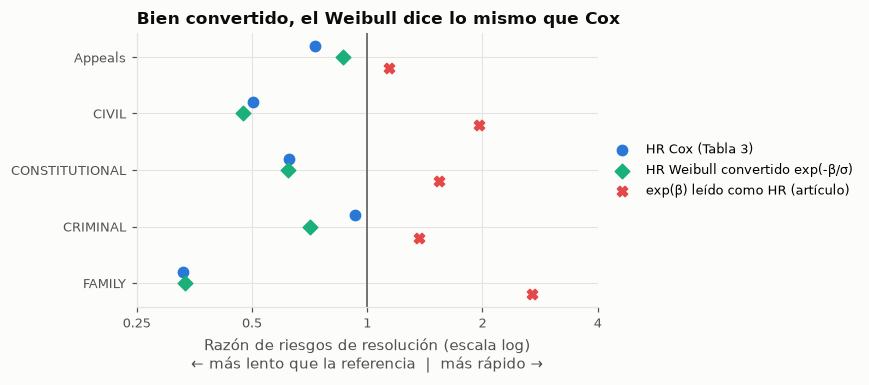

In [21]:
fuente = res_real
sigma = fuente["escalas"]["Weibull"]
covs = ["Appeals", "CIVIL", "CONSTITUTIONAL", "CRIMINAL", "FAMILY"]
interpretacion = pd.DataFrame({
    "HR Cox (Tabla 3)": [cfg.TABLA3[c][1] for c in covs],
    "HR Weibull convertido exp(-β/σ)": [np.exp(-cfg.TABLAS_AFT["Weibull"][c][0] / sigma) for c in covs],
    "exp(β) leído como HR (artículo)": [np.exp(cfg.TABLAS_AFT["Weibull"][c][0]) for c in covs],
}, index=covs)
interpretacion.to_csv(cfg.RESULTS / "interpretacion_weibull_vs_cox.csv")
print(f"sigma (Scale de survreg, datos reales) = {sigma:.3f}")
display(interpretacion)
g.hr_cox_vs_weibull(interpretacion)
plt.show()

La misma confusión explica por qué el artículo dice, en la sección de resultados, que los casos apelados son **más cortos** según Weibull y luego, en la discusión y la conclusión, que tienen **menor** riesgo de resolución. La lectura correcta es la segunda: con los dos modelos los casos apelados tardan más.

#### b) El AIC de Cox no se puede comparar con el de los paramétricos

La Tabla 8 compara 1.915.086 (Cox) con 713.383 (Weibull) y concluye que Weibull ajusta mejor. Ese número no permite esa conclusión por dos razones:

- Cox maximiza una verosimilitud **parcial**, que no modela el riesgo base $h_0(t)$; los paramétricos maximizan la verosimilitud **completa** de $T$. Son funciones distintas, en escalas distintas.
- Cox se ajustó con 92.405 casos (incluye los de 0 meses) y los paramétricos con 81.266. Ni siquiera se evalúan sobre los mismos datos.

Dos alternativas sí comparables, sobre los mismos casos: el índice de concordancia (qué tan bien ordena el modelo los casos según su duración) y los residuos de Cox-Snell, que el artículo menciona en la metodología pero nunca muestra. Si un modelo es correcto, el hazard acumulado de sus residuos sigue la recta de 45 grados.

,C-index (sim),C-index (real),Desvío Cox-Snell (sim),Desvío Cox-Snell (real)
Cox PH,0.624,0.605,0.226,0.250
Weibull,0.624,0.606,0.116,0.206
Exponential,0.624,0.606,0.230,0.311
Log-normal,0.624,0.607,0.498,0.387
Log-logistic,0.624,0.607,0.546,0.449


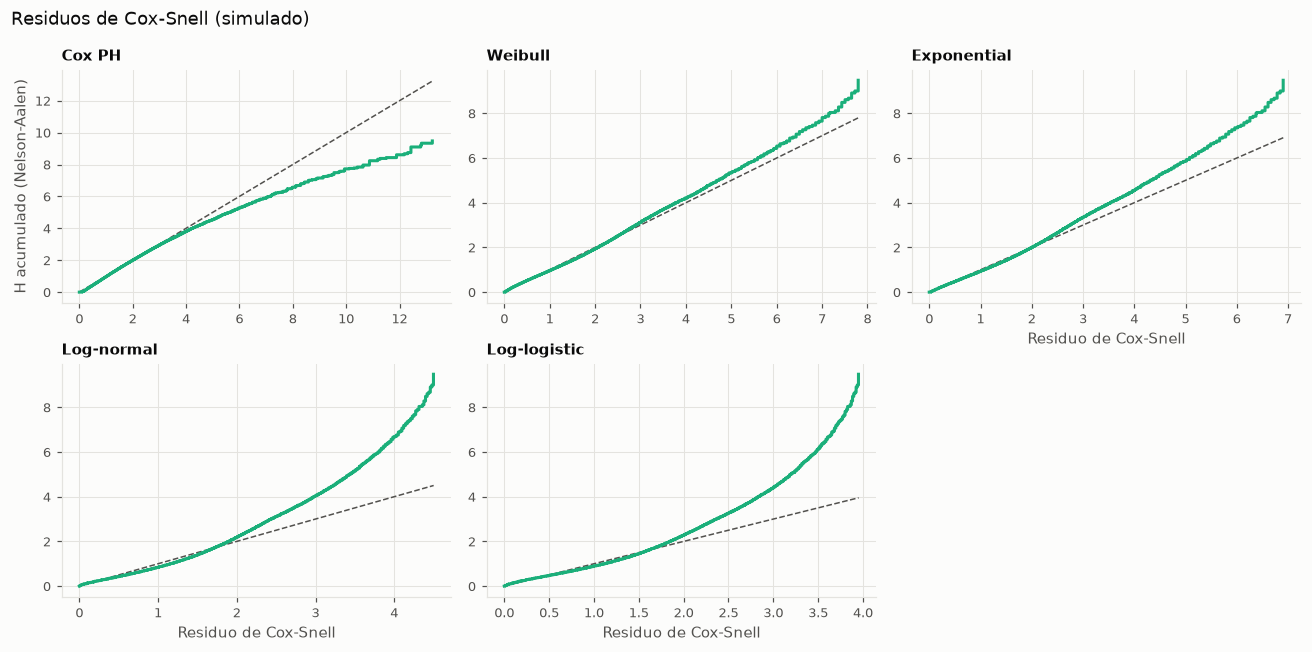

In [22]:
comparables = pd.DataFrame({
    "C-index (sim)": res_sim["c_index"], "C-index (real)": res_real["c_index"],
    "Desvío Cox-Snell (sim)": res_sim["cox_snell_desvio"],
    "Desvío Cox-Snell (real)": res_real["cox_snell_desvio"],
})
comparables.to_csv(cfg.RESULTS / "comparacion_modelos_metricas_comparables.csv")
display(comparables)
g.cox_snell(res_sim["cox_snell"], "Residuos de Cox-Snell (simulado)", "10_cox_snell_simulado")
plt.show()

El C-index es prácticamente igual en los cinco modelos (0.62 en la simulación y 0.61 en los datos reales). Con dos covariables categóricas, todos los modelos ordenan los casos casi igual: no hay uno que "prediga mejor" en el sentido de discriminar. Lo que cambia es qué tan bien describe cada uno la **forma** de la distribución del tiempo, y ahí los residuos de Cox-Snell sí favorecen a Weibull (menor desvío respecto a la recta), en ambas bases. La conclusión del artículo se sostiene, pero por un camino distinto al AIC de la Tabla 8.

#### c) Weibull también es un modelo de riesgos proporcionales

La discusión dice que la superioridad de Weibull sugiere que el supuesto de riesgos proporcionales no se cumple. Pero una regresión Weibull **es** un modelo PH (por eso funciona la conversión del punto a). Si el supuesto PH falla, falla para los dos. Lo que sí permite evaluarlo es la prueba de residuos de Schoenfeld, que el artículo no reporta:

In [23]:
ph = pd.DataFrame({"p (sim)": res_sim["prueba_ph"]["p"], "p (real)": res_real["prueba_ph"]["p"],
                   "estadístico (real)": res_real["prueba_ph"]["test_statistic"]})
ph.to_csv(cfg.RESULTS / "prueba_riesgos_proporcionales.csv")
display(ph)

,p (sim),p (real),estadístico (real)
Appeals,4.491e-16,0.000e+00,6444.274
CIVIL,1.067e-04,4.010e-01,0.705
CONSTITUTIONAL,3.329e-01,6.833e-03,7.316
CRIMINAL,4.196e-03,7.942e-12,46.780
FAMILY,4.165e-11,2.645e-11,44.424


En los datos reales la apelación viola el supuesto de forma muy marcada (estadístico cercano a 6.400) y también penal y familia. Ni Cox ni Weibull con estas covariables capturan ese efecto que cambia en el tiempo; un modelo con estratos por apelación, interacciones con el tiempo o un AFT log-normal con efectos por tipo serían candidatos naturales.

#### d) Otros puntos menores

- Las DE de la Tabla 2 son los límites del intervalo de confianza (sección 6.2).
- El texto reporta 91.405 registros y la base tiene 92.405.
- Con un solo caso censurado, las curvas de Kaplan-Meier son simplemente la distribución empírica de las duraciones de los casos **cerrados**. Leerlas como "probabilidad de que un caso siga sin resolverse" exige recordar que la muestra solo incluye casos que se cerraron entre 2018 y 2022. Esa es la condición que se modifica en la extensión.

## 7. Extensión: qué pasa si se incluyen los casos abiertos

**Condición modificada (una sola):** el mecanismo de observación. Todo lo demás (población latente, parámetros, modelos, filtro de duración positiva) se mantiene igual.

- **Diseño A, como el artículo:** entran solo los casos dispuestos entre 2018 y 2022.
- **Diseño B, cohorte con censura:** entran todos los casos radicados entre 2012 y 2022; los que siguen abiertos a diciembre de 2022 quedan censurados en ese momento.

La simulación permite algo que los datos reales no: conocer la duración completa de cada caso latente. Esa es la **verdad** contra la que se miden los dos diseños.

Pregunta: ¿cuánto se equivoca el diseño del artículo al estimar duraciones, y cuánto corrige el análisis de supervivencia cuando sí se le da censura?

In [24]:
resultado_ext = ext.ejecutar(latente)
resultado_ext["tamanos"].to_csv(cfg.RESULTS / "extension_tamanos.csv")
resultado_ext["resumen"].to_csv(cfg.RESULTS / "extension_resumen_km.csv", index=False)
resultado_ext["razones_tiempo"].to_csv(cfg.RESULTS / "extension_razones_tiempo_weibull.csv")
display(resultado_ext["tamanos"])

,n,eventos,censura_%
Verdad (duración completa),233253.0,233253.0,0.000
A: artículo (solo dispuestos 2018-2022),91405.0,91405.0,0.000
B: cohorte con censura,233253.0,161136.0,30.918


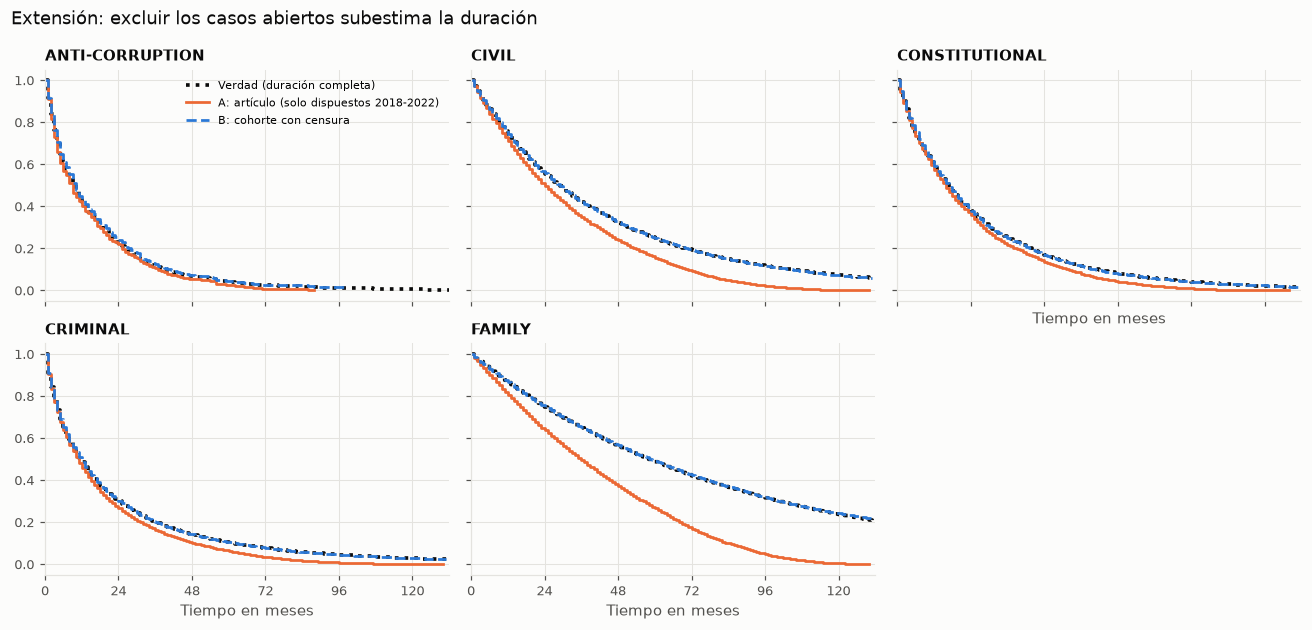

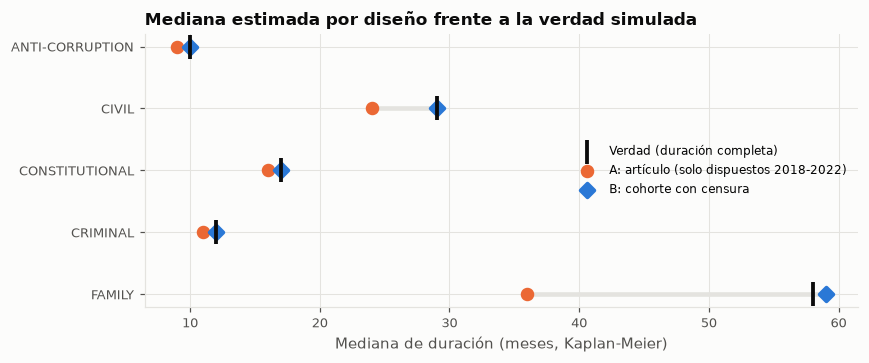

In [25]:
g.extension_km(resultado_ext["curvas"])
plt.show()
g.extension_medianas(resultado_ext["resumen"])
plt.show()

In [26]:
err_mediana = ext.error_relativo(resultado_ext["resumen"], "mediana")
err_rmst = ext.error_relativo(resultado_ext["resumen"], f"RMST_{ext.HORIZONTE_RMST}")
errores = pd.concat({"error % mediana": err_mediana, f"error % duración media a {ext.HORIZONTE_RMST} meses": err_rmst}, axis=1)
errores.to_csv(cfg.RESULTS / "extension_errores_relativos.csv")
display(errores)
display(resultado_ext["razones_tiempo"].round(2))

error % mediana                              error % duración media a 60 meses                       
diseno          A: artículo (solo dispuestos 2018-2022) B: cohorte con censura A: artículo (solo dispuestos 2018-2022) B: cohorte con censura
case_type                                                                                                                                    
ANTI-CORRUPTION                                   -10.0                    0.0                                    -6.4                    2.9
CIVIL                                             -17.2                    0.0                                   -10.9                    0.3
CONSTITUTIONAL                                     -5.9                    0.0                                    -6.6                    0.0
CRIMINAL                                           -8.3                    0.0                                    -9.4                    0.4
FAMILY                                            -37.9                    1.7                                   -17.3                    0.3

,Verdad (duración completa),A: artículo (solo dispuestos 2018-2022),B: cohorte con censura
Appeals,1.90,1.37,1.84
CIVIL,2.30,1.99,2.33
CONSTITUTIONAL,1.92,1.66,1.84
CRIMINAL,1.35,1.23,1.24
FAMILY,5.84,2.92,5.98


**Lectura.**

- El diseño del artículo (A) **subestima** la duración de todos los tipos. El sesgo crece con la duración típica: familia pasa de una mediana verdadera de 58 meses a una estimada de 36 (−38 %); civil, de 29 a 24 (−17 %); anticorrupción y penal, entre −8 % y −10 %. La razón es mecánica: un caso que tarda mucho tiene más probabilidad de seguir abierto al corte o de haberse radicado antes de que la ventana pudiera "verlo cerrar", así que la muestra de casos cerrados está cargada hacia los rápidos.
- El diseño con censura (B) recupera la verdad casi exactamente (error de 0 a 2 %), aunque el 31 % de sus casos está censurado. Es la razón de ser del análisis de supervivencia: usar la información parcial de los casos abiertos en lugar de descartarlos.
- El sesgo también llega a los coeficientes: la razón de tiempos de familia frente a anticorrupción es 5.8 en la verdad, 6.0 con censura y 2.9 en el diseño del artículo. El diseño A no solo acorta las duraciones, también **comprime las diferencias** entre tipos de caso.

Esta magnitud depende de los supuestos S4 a S6: la Tabla 1 es compatible con más de una distribución latente, y otra elección daría otro tamaño de sesgo. La dirección del sesgo, en cambio, no depende del supuesto: excluir los casos abiertos siempre favorece a los cortos.

**Consecuencia para dimensionar equipos.** Por la ley de Little, el número promedio de casos abiertos es $L = \lambda \cdot W$ (tasa de llegada por duración media). Si la duración media se subestima un 17 % (familia, horizonte de 60 meses), la carga de trabajo, y con ella el personal requerido, se subestima en la misma proporción.

## 8. Conclusión

**Qué fue posible recrear**

- El procedimiento completo del artículo en Python: estadísticos descriptivos, prueba t, Kaplan-Meier con log-rank, Cox, los cuatro modelos paramétricos y la tabla de AIC.
- Una base simulada de 91.405 casos que reproduce la Tabla 1 y, sin haber sido calibrada para ello, la dirección y el orden de todos los efectos de las Tablas 3 a 7 y el ranking de la Tabla 8.
- Con los datos reales como referencia, las Tablas 3 a 8 exactamente, lo que permitió atribuir cada diferencia a un supuesto concreto de la simulación.

**Qué no fue posible recrear**

- La magnitud del efecto de apelación con un único efecto común: la Tabla 1 y la Tabla 4 no son compatibles bajo ese supuesto.
- La masa de casos penales resueltos en 0 meses, que una Weibull por tipo no genera.
- Los valores absolutos del AIC, que dependen del tamaño de la muestra.
- Los resultados de la sección de condados y del modelo gamma del Rmd, que el artículo no publica.

**Qué deja para el trabajo de grado**

1. **Extraer también los casos abiertos.** Si la base de compras se arma filtrando casos cerrados en un periodo, los tiempos de ciclo saldrán sesgados hacia abajo, y más en las categorías lentas. Hay que conservar los casos abiertos con su fecha de corte y una marca de censura.
2. **Interpretar bien los modelos AFT.** Un coeficiente de `survreg` o `WeibullAFTFitter` es una razón de tiempos. Para la simulación de capacidad es justamente lo que se necesita: cuánto más dura un tipo de caso.
3. **Comparar modelos sobre los mismos datos y con la misma verosimilitud**, y complementar el AIC con residuos de Cox-Snell y con el C-index.
4. **Revisar el supuesto de riesgos proporcionales** antes de elegir entre Cox y un paramétrico, y considerar efectos que cambien por tipo de caso (interacciones).
5. **La calibración por simulación funciona** como punto de partida del simulador de carga de trabajo: con medias, medianas y DE por categoría se puede construir un generador de tiempos de ciclo coherente con los datos y sobre él estimar el personal requerido.

### Preguntas para preparar la sustentación

Antes de presentar, intenta responder estas preguntas sin mirar el notebook:

1. Si el coeficiente de familia en la Weibull de `survreg` es +0.992, ¿qué le pasa a la duración de un caso de familia frente a uno de anticorrupción? ¿Cómo lo pasarías a razón de riesgos si $\sigma = 0.903$?
2. ¿Por qué el AIC de Cox de la Tabla 8 no puede ir en la misma columna que el de Weibull? Piensa en qué función maximiza cada modelo y con cuántos casos.
3. Si Weibull también es un modelo de riesgos proporcionales, ¿qué evidencia sí te permitiría afirmar que ese supuesto falla?
4. En la extensión, ¿por qué excluir los casos abiertos afecta más a familia que a anticorrupción?
5. En tu base de compras, ¿qué casos quedarían censurados y qué pasaría con la estimación de personal si los eliminaras?